#Titanic Dataset - Exploratory Data Analyis
In this notebook, I explore the titanic dataset to determine which factors (age,sex,class,fare) most strongly influenced the passenger survival

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

#Set style for all plots
sns.set_theme(style = "whitegrid")

#load data from the data/titanic.csv
df = pd.read_csv("../data/titanic.csv")

#Show the first 5 rows
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
#Get summary of the dataset
print(df.shape)
df.info()

(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


- The dataset has 891 rows and 12 columns, where total entries are 891(0 to 890).
- There are 12 columns (factors) from 0 to 11.
- Factors: Age, Cabin and embarked has missing values.

In [4]:
#Counting missing values and calculating percentages
missing_count = df.isna().sum()
missing_percentage = (df.isna().sum()/ len(df)) * 100

#Combine into Dataframe for easy view
missing_df = pd.DataFrame({'Missing Count': missing_count, 'Missing %': missing_percentage})
missing_df[missing_df['Missing Count']> 0].sort_values(by='Missing %', ascending=False)

,Missing Count,Missing %
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


Cabin: Over 70% missing- needs to be dropped since to many missing values
Age: About 20% missing - cannot be dropped so fill with median value
Embarked: Only 2 missing - cannot drop so fill with mode

In [5]:
#Drop the Cabin column
df = df.drop(columns=['Cabin'])

#Fill the Age with mean value
df['Age'] = df['Age'].fillna(df['Age'].median())

#Fill the Embarked with mode
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])

print(df.isna().sum().sum())

0


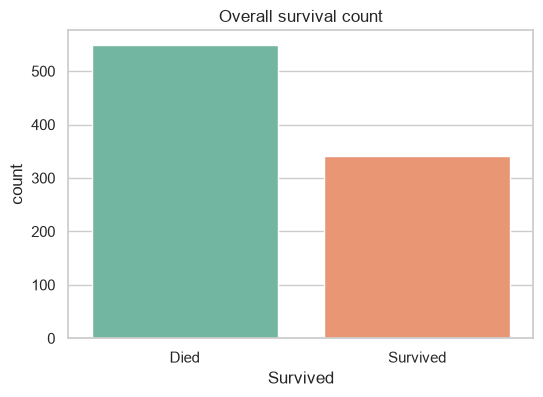

In [13]:
# Plot 1: Survival Count (0 = Died and 1 = Survived)
fig, ax = plt.subplots(figsize = (6,4))
sns.countplot(data = df, x = "Survived", hue = "Survived", legend = False, palette = "Set2", ax = ax)
ax.set_title("Overall survival count")
ax.set_xticks([0,1])
ax.set_xticklabels(["Died", "Survived"])
plt.show()

The Dataset is imbalanced. Number of people died  is far more than the number of survived.

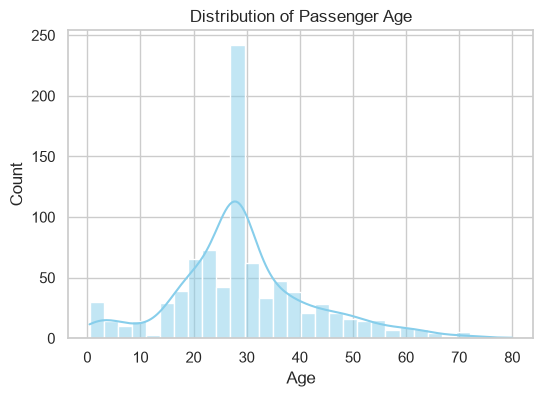

In [6]:
# Plot 2: Distribution of Age
fig, ax = plt.subplots(figsize=(6,4))
sns.histplot(data = df, x = "Age", bins = 30, kde = True, color = "skyblue",ax = ax)
ax.set_title("Distribution of Passenger Age")
plt.show()

Most passenger are young adults around age 30. The distribution is right skewed, with fewer older individuals compared with younger ones.

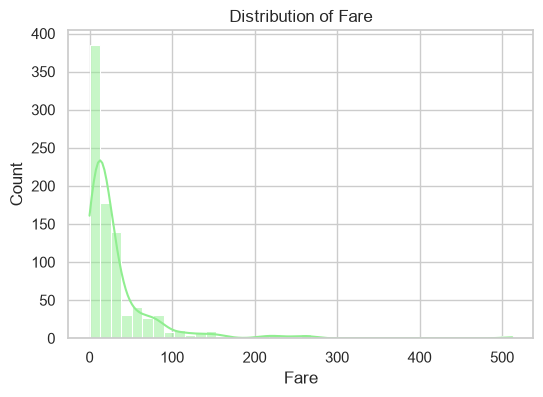

In [7]:
# Plot 3: Distribution of Fare
fig,ax = plt.subplots(figsize = (6,4))
sns.histplot(data = df, x = "Fare", bins = 40, kde = True, color = "lightgreen", ax = ax)
ax.set_title("Distribution of Fare")
plt.show()

It is skewed to the right, with most fares clustered near zero and long tail towards higer fare prices.

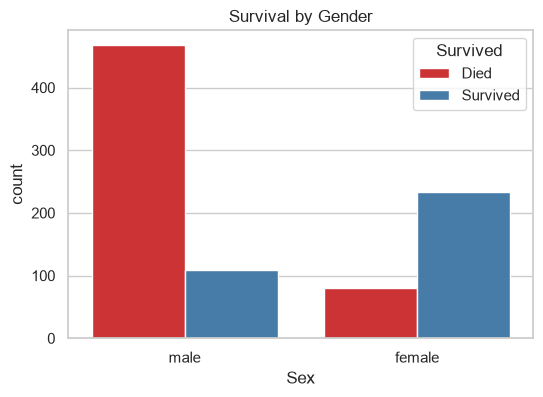

In [105]:
# Plot 4: Survival by gender
fig,ax = plt.subplots(figsize=(6,4))
sns.countplot(data = df , x = "Sex", hue="Survived", palette = "Set1",ax = ax)
ax.set_title("Survival by Gender")
ax.legend(title ="Survived",labels =["Died","Survived"])
plt.show()

Females have drastically more survival rate than male.

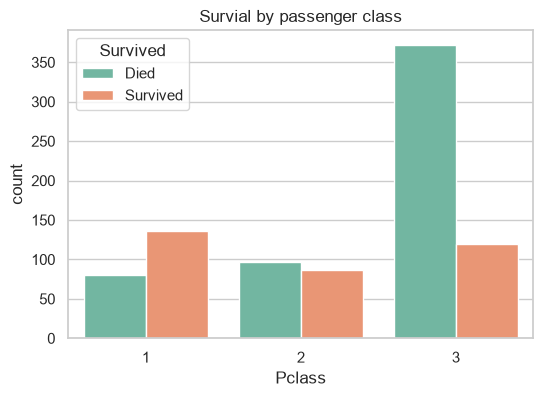

In [129]:
# Plot 5: Survival by Passenger Class
fig,ax = plt.subplots(figsize = (6,4))
sns.countplot(data = df, x = "Pclass",hue = "Survived", palette = "Set2",ax = ax)
ax.set_title("Survial by passenger class")
ax.legend(title = "Survived",labels = ["Died","Survived"])
plt.show()

1st Class passenger has more survival rate compared to 2nd and 3rd, whereas number of passenger died is drastically higher of 3rd Class than 1st and 2nd class.

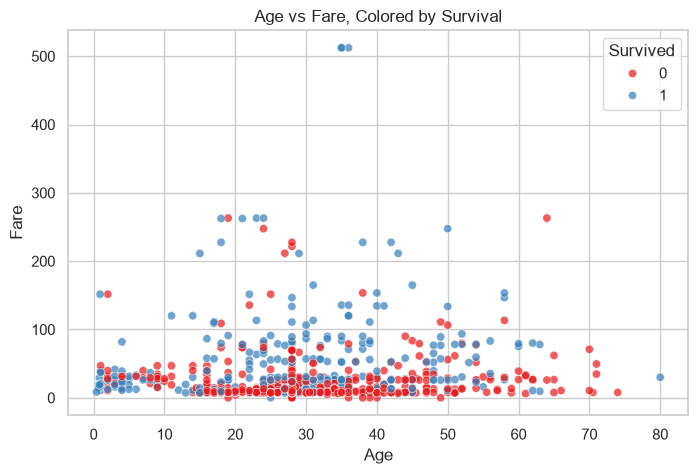

In [131]:
# Plot 6: Age vs Fare Survival
fig,ax = plt.subplots(figsize = (8,5))
sns.scatterplot(data = df, x = "Age", y = "Fare",hue = "Survived", palette= "Set1",alpha = 0.7,ax =ax)
ax.set_title("Age vs Fare, Colored by Survival")
plt.show()

People who paid higher fares (mostly of 1st class) had more chance of surviving regardless of age. 

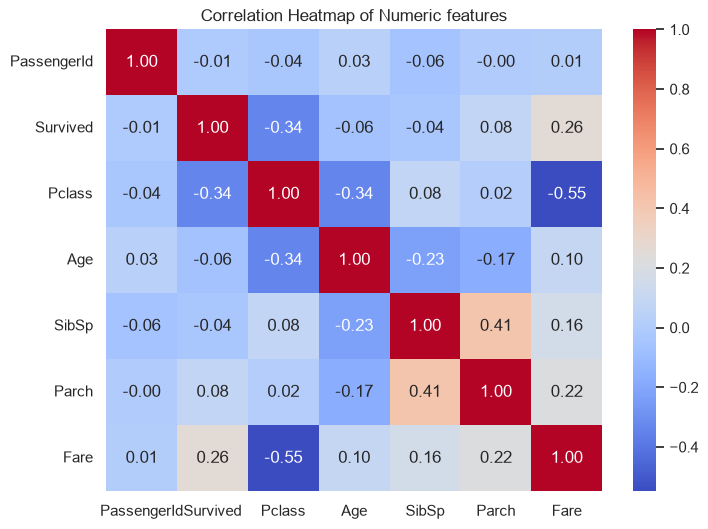

In [26]:
# Plot 7: Correlation Heatmap
fig, ax = plt.subplots(figsize = (8,6))
corr = df.corr(numeric_only= True)
sns.heatmap(data = corr, annot = True, cmap = "coolwarm", fmt = ".2f", ax=ax)
ax.set_title("Correlation Heatmap of Numeric features")
plt.show()

Survival is most strongly correlated with the passenger class (-0.34), showing that lower class(1st class) had more survival rate. Fare has also positive correlation(0.26), meaning higher fares were linked to better survival chance. 

## Key Insights
1. Females had a significantly higher survival rate compared to males.
2. Passenger class was a strong predictor of survival: 1st class passengers had the highest survival rate.
3. Paying a higher fares was positively correlated with a higher chance of survival.